Importing Required Libraries

In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense,  Dropout, GRU
from keras.optimizers import SGD
import tensorflow as tf
import math
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ModuleNotFoundError: No module named 'joblib'

Importing Matplotlib for Visualization

In [2]:
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

Loading the Dataset

In [3]:
dataset = pd.read_csv('GOOGL_stock_data.csv', index_col='Date', parse_dates=['Date'])

Displaying the First Few Rows

In [4]:
dataset.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,10.535383,10.863273,10.428164,10.852302,524323152,GOOGL
2006-01-04,11.068484,11.194653,10.965005,11.101896,610844544,GOOGL
2006-01-05,11.120847,11.259234,11.008641,11.251504,431899668,GOOGL
2006-01-06,11.391886,11.731745,11.301374,11.611062,709565724,GOOGL
2006-01-09,11.629763,11.804056,11.493371,11.641981,511164324,GOOGL


Checking the Shape of the Dataset

In [5]:
dataset.shape

(4806, 6)

Splitting Data into Training & Testing Sets

In [6]:
training_set = dataset[:'2022'].iloc[:,1:2].values
test_set = dataset['2023':].iloc[:,1:2].values

Visualizing Training and Testing Sets

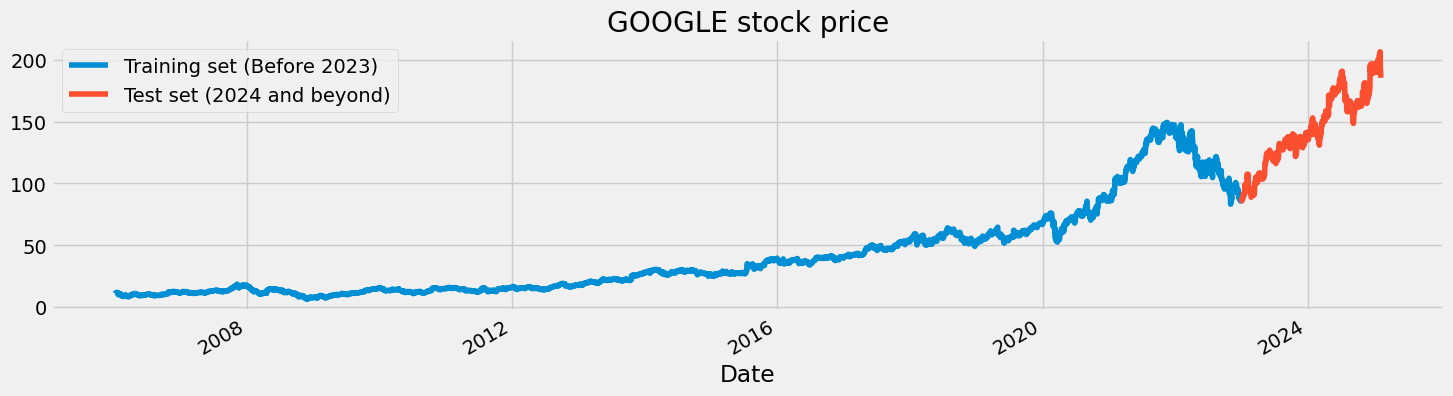

In [7]:
dataset["Close"][:'2022'].plot(figsize=(16,4),legend=True)
dataset["Close"]['2023':].plot(figsize=(16,4),legend=True)
plt.legend(['Training set (Before 2023)','Test set (2024 and beyond)'])
plt.title('GOOGLE stock price')
plt.show()

Scaling the training set

In [8]:
sc = MinMaxScaler(feature_range=(0,1))
training_set_scaled = sc.fit_transform(training_set)

we create a data structure with 60 timesteps and 1 output .So for each element of training set, we have 60 previous training set elements 

In [9]:
timestamp_structure = 60

Creating Training Data Sequences

In [10]:
X_train = []
y_train = []
for i in range(timestamp_structure,len(training_set_scaled)):
    X_train.append(training_set_scaled[i-timestamp_structure:i,0])
    y_train.append(training_set_scaled[i,0])
X_train, y_train = np.array(X_train), np.array(y_train)

Reshaping X_train for efficient modelling

In [11]:
X_train = np.reshape(X_train, (X_train.shape[0],X_train.shape[1],1))

Defining Model Hyperparameters

In [12]:
epochs = 100
batch_size = 32
loss = 'mean_squared_error'
optimizer = 'rmsprop'

Building and Training the GRU Model

In [13]:
regressorGRU = Sequential()
regressorGRU.add(GRU(units=50, return_sequences=True, input_shape=(X_train.shape[1],1), activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(GRU(units=50, return_sequences=True, input_shape=(X_train.shape[1],1), activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(GRU(units=50, return_sequences=True, input_shape=(X_train.shape[1],1), activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(GRU(units=50, activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(Dense(units=1))
regressorGRU.compile(optimizer=optimizer,
                     loss=loss)
regressorGRU.fit(X_train,y_train,epochs=epochs, batch_size=batch_size)

c:\Users\Asus\Downloads\stock-price-prediction-master\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 23s 86ms/step - loss: 0.0113
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - loss: 0.0029
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - loss: 0.0023
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 22s 167ms/step - loss: 0.0022
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 22s 164ms/step - loss: 0.0021
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 23s 176ms/step - loss: 0.0019
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 23s 176ms/step - loss: 0.0018
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 24s 183ms/step - loss: 0.0019
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 26s 193ms/step - loss: 0.0015
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 25s 191ms/step - loss: 0.0015
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 25s 186ms/step - loss: 0.0016
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 40s 179ms/step - loss: 0.0016
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 23s 174ms/step - loss: 0.0014
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 22s 168ms/step - loss: 0.0015
Epoc

Preparing Test Data for Prediction

In [ ]:
dataset_total = pd.concat((dataset["High"][:'2023'],dataset["High"]['2024':]),axis=0)
inputs = dataset_total[len(dataset_total)-len(test_set) - timestamp_structure:].values
inputs = inputs.reshape(-1,1)
inputs  = sc.transform(inputs)

Creating X_test and Making Predictions

In [15]:
X_test = []
for i in range(timestamp_structure,len(inputs)):
    X_test.append(inputs[i-timestamp_structure:i,0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0],X_test.shape[1],1))
GRU_predicted_stock_price = regressorGRU.predict(X_test)
GRU_predicted_stock_price = sc.inverse_transform(GRU_predicted_stock_price)

17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step


Plotting Real vs. Predicted Prices

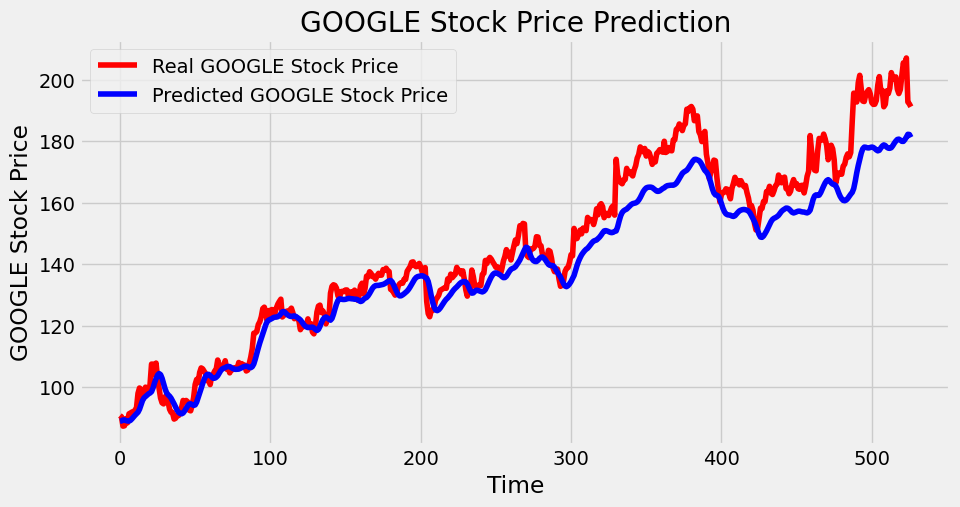

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(test_set, color='red',label='Real GOOGLE Stock Price')
plt.plot(GRU_predicted_stock_price, color='blue',label='Predicted GOOGLE Stock Price')
plt.title('GOOGLE Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('GOOGLE Stock Price')
plt.legend()
plt.show()

Calculating Model Performance Metrics

In [17]:
# Calculate regression metrics
mse = mean_squared_error(test_set, GRU_predicted_stock_price)
rmse = math.sqrt(mse)
mae = mean_absolute_error(test_set, GRU_predicted_stock_price)
r2 = r2_score(test_set, GRU_predicted_stock_price)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error (MSE): 83.0638
Root Mean Squared Error (RMSE): 9.1139
Mean Absolute Error (MAE): 7.0347
R² Score: 0.9045


Final Visualizing

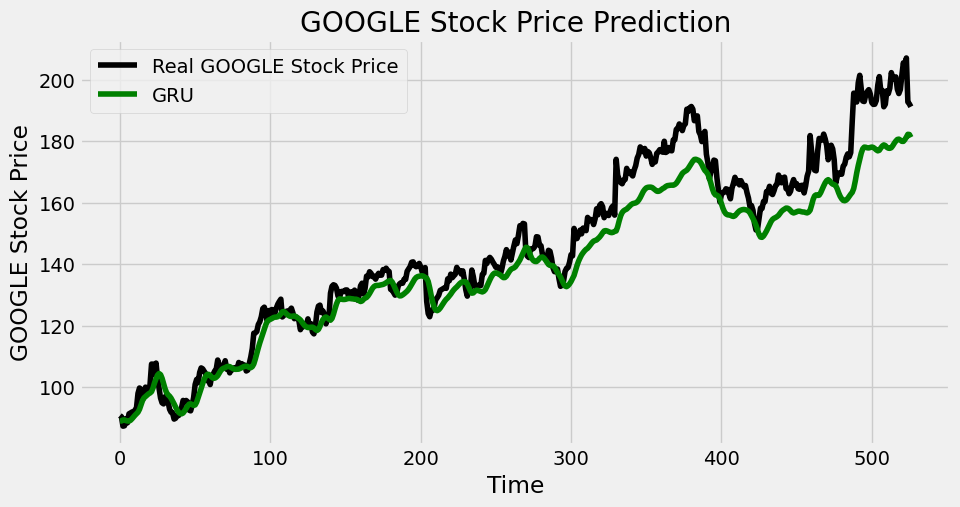

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(test_set, color='black',label='Real GOOGLE Stock Price')
plt.plot(GRU_predicted_stock_price, color='green',label='GRU')
plt.title('GOOGLE Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('GOOGLE Stock Price')
plt.legend()
plt.show()

Saving the Model & Scaler

In [19]:
# Add these imports at the top
from joblib import dump
import keras

# Save model
regressorGRU.save('gru_model_final.keras')

# Save scaler
dump(sc, 'scaler_final.joblib')

['scaler_final.joblib']